<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI Packages Worker](https://github.com/Query-farm/vgi-software-packages)

Search software packages and inspect native release metadata with optional authentication.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-software-packages/blob/main/notebooks/03_discovery_is_not_a_dependency_plan.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-software-packages/blob/main/notebooks/README.md)


## 03 · Discovery is not a dependency plan

Can a source answer a search, and do returned dependency declarations describe what
would be installed? First inspect two registry contracts, then use a bounded npm search
for discovery and inspect an exact PyPI release's dependency text. Keep source identity,
provider-selected package metadata, version inventory and marker conditions separate.

All results are live anonymous public metadata. No package or dependency is installed,
and no dependency marker or version expression is resolved by this notebook.

### Include or exclude declarations mentioning extras

Use **INCLUDE_EXTRAS = False**, then try **True**. This changes a local display filter
over the complete returned pandas 2.2.3 declarations. A lexical check for the marker
variable `extra` labels those rows; it does not evaluate PEP 508 marker semantics.
Other environment conditions remain visible even in the default selection. A declaration
count is not an installed-package count.

In [1]:
INCLUDE_EXTRAS = False  # Experiment: True

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The base
install preserves compatible preloaded plotting/kernel packages; local publication uses
the optional `[runner]` extra. Package/extension/native-worker downloads and these live
public metadata requests require internet. No checkout, Bun build, package installation
or container runtime is required. Hosted Colab is not tested; fresh preloaded Python 3.12
notebook-only execution checks each of the two native launcher paths. See [setup and
provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.44":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.44"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.44":
    raise RuntimeError("Install shared tools 0.3.44, restart, and Run All.")

In [3]:
import json
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("software-packages")
from public_sources import PublicSources

%matplotlib inline
theme()
STARTED_UTC = datetime.now(UTC).isoformat(timespec="seconds")
public = PublicSources()
session = connect(globals())
connection = session.connection
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert connection.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
Path("artifacts").mkdir(exist_ok=True)

if type(INCLUDE_EXTRAS) is not bool:
    raise ValueError("INCLUDE_EXTRAS must be a boolean")

### Anonymous public reads with an empty credential store

The helper supplies only anonymous public PyPI, npm and Quay endpoints and an empty
disposable metadata cache. Shared setup opens an empty temporary SQL-secret directory,
disables persistence and JupySQL default-INI autoload, and fixes UTC for all SQL cursors.
No saved secrets are read and no SQL credentials are created. Cleanup closes the session
and removes temporary configuration/cache state, restoring inherited settings.

These are **live public metadata reads**, with no recording or fallback. Retrieval time
is not publication time. Missing provider fields remain NULL; metadata sizes and hashes
do not establish package installation, layer-payload integrity or runtime behavior.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'packages' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-software-packages@v0.2.0/vgi-packages-worker');

,Success


### Adapter support and search readiness are different facts

The reference relations are both catalog tables and zero-argument functions with the
same logical names. Join `sources`, `capabilities` and `source_status` by source ID.
The anonymous npm adapter supports native search. PyPI search needs a prepared name
index, which this fresh cache intentionally does not contain; its live package/version/
artifact/dependency reads still work. A native `ready` value reports adapter availability,
not a remote health check. NULL native completeness is not a complete-ecosystem claim.

Use npm search only to discover a bounded set of names containing the requested concept.
The name `apache-arrow` in npm is a registry-specific package identity, not an alias for
a Python package. Provider ranking and nullable scores are not quality measurements.

In [5]:
%%sql
CREATE TABLE sources AS SELECT * FROM packages.main.sources;
CREATE TABLE capabilities AS SELECT * FROM packages.main.capabilities;
CREATE TABLE source_status AS SELECT * FROM packages.main.source_status;
CREATE TABLE registry_contract AS
SELECT s.source_id,s.ecosystem,s.endpoint,s.authentication,c.operation,c.supported,c.search_mode,
 st.ready AS search_ready,st.complete AS indexed_input_complete,st.error AS index_status
FROM sources s JOIN capabilities c USING(source_id) JOIN source_status st USING(source_id);
CREATE TABLE search_results AS SELECT * FROM packages.main.search('npm_public','apache-arrow',8);
SELECT source_id,endpoint,authentication,search_mode,search_ready,indexed_input_complete,index_status
FROM registry_contract WHERE operation='search' ORDER BY source_id;
SELECT source_id,name,version,score,search_mode,observed_at FROM search_results ORDER BY name;
SELECT count(*) AS returned_names,count(*)=8 AS reached_requested_limit,
 count(score) AS supplied_scores,count(DISTINCT source_id) AS registries FROM search_results;

,returned_names,reached_requested_limit,supplied_scores,registries
0,8,True,8,1


In [6]:
%%sql contract <<
SELECT * FROM registry_contract ORDER BY source_id,operation;

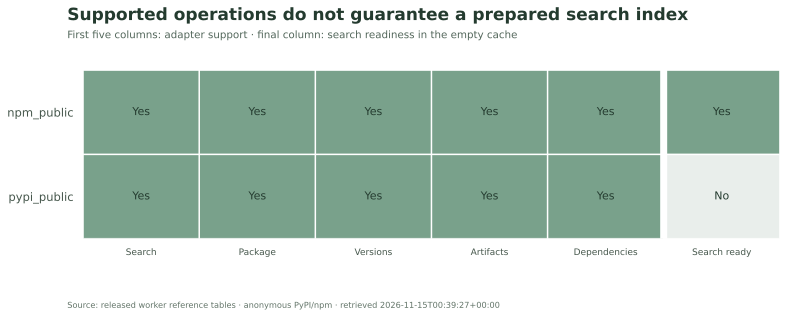

In [7]:
operations = ["search", "package", "versions", "artifacts", "dependencies"]
rows = sorted(contract.source_id.unique())
values = np.array(
    [
        [
            int(contract.loc[(contract.source_id == s) & (contract.operation == o), "supported"].iloc[0])
            for o in operations
        ]
        + [int(contract.loc[contract.source_id == s, "search_ready"].iloc[0])]
        for s in rows
    ]
)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.imshow(
    values, cmap=plt.matplotlib.colors.ListedColormap(["#E9EEEB", "#79A18B"]), vmin=0, vmax=1, aspect="auto"
)
for i, _s in enumerate(rows):
    for k, _o in enumerate(operations + ["ready"]):
        ax.text(k, i, "Yes" if values[i, k] else "No", ha="center", va="center", fontsize=11)
for boundary in np.arange(-0.5, 6, 1):
    ax.axvline(boundary, color="white", linewidth=1.5)
for boundary in np.arange(-0.5, 2, 1):
    ax.axhline(boundary, color="white", linewidth=1.5)
ax.axvline(4.5, color="white", linewidth=7)
ax.set(
    xticks=range(6),
    xticklabels=["Search", "Package", "Versions", "Artifacts", "Dependencies", "Search ready"],
    yticks=range(2),
    yticklabels=rows,
)
ax.tick_params(axis="x", labelsize=9)
finish(
    fig,
    "Supported operations do not guarantee a prepared search index",
    "First five columns: adapter support · final column: search readiness in the empty cache",
    f"Source: released worker reference tables · anonymous PyPI/npm · retrieved {STARTED_UTC}",
    name="registry-readiness",
)

### Select an exact version without inventing a newest-first order

`package` exposes provider-selected current project metadata, while `versions` inventories
native version strings. Neither a lexical maximum nor the first row establishes the
newest compatible release. We deliberately choose **pandas 2.2.3**, the release used in
notebook 01, verify its presence and fetch its declarations explicitly.

The current project description may concern another version; its Requires-Python field
must not be silently applied to 2.2.3. Missing version publication dates and yanking
fields remain missing. A display inventory below the row budget is bounded evidence,
not a guarantee of future upstream completeness.

In [8]:
%%sql
CREATE TABLE project AS SELECT * FROM packages.main.package('pypi_public','pandas',max_results:=1000);
CREATE TABLE versions AS SELECT * FROM packages.main.versions('pypi_public','pandas',max_results:=1000);
CREATE TABLE declarations AS SELECT * FROM packages.main.dependencies('pypi_public','pandas','2.2.3',max_results:=1000);
CREATE TABLE declaration_flags AS
SELECT *,regexp_matches(coalesce(condition,''),'(^|[^a-zA-Z0-9_])extra([^a-zA-Z0-9_]|$)') AS mentions_extra,
 CASE WHEN condition IS NULL THEN 'No marker supplied'
 WHEN regexp_matches(condition,'(^|[^a-zA-Z0-9_])extra([^a-zA-Z0-9_]|$)') THEN 'Mentions extra'
 ELSE 'Other environment marker' END AS marker_group,
 {{INCLUDE_EXTRAS}} OR NOT mentions_extra AS selected FROM declarations;
SELECT source_id,name,version AS provider_selected_version,json_extract_string(metadata,'$.requires_python') AS current_requires_python,
 homepage,repository,license,observed_at FROM project;
SELECT count(*) AS native_version_rows,count(*)<1000 AS below_requested_limit,
 count(*) FILTER(WHERE version='2.2.3') AS exact_target_rows,
 count(published_at) AS supplied_publication_times,count(yanked) AS supplied_yank_flags FROM versions;
SELECT dependency,requirement,condition,declaration_context,selected FROM declaration_flags
ORDER BY selected DESC,dependency,requirement;

,dependency,requirement,condition,declaration_context,selected
0,numpy,"numpy>=1.22.4; python_version < ""3.11""","python_version < ""3.11""",PyPI release metadata; per-file metadata may d...,True
1,numpy,"numpy>=1.23.2; python_version == ""3.11""","python_version == ""3.11""",PyPI release metadata; per-file metadata may d...,True
2,numpy,"numpy>=1.26.0; python_version >= ""3.12""","python_version >= ""3.12""",PyPI release metadata; per-file metadata may d...,True
3,python-dateutil,python-dateutil>=2.8.2,None,PyPI release metadata; per-file metadata may d...,True
4,pytz,pytz>=2020.1,None,PyPI release metadata; per-file metadata may d...,True
...,...,...,...,...,...
80,xlrd,"xlrd>=2.0.1; extra == ""excel""","extra == ""excel""",PyPI release metadata; per-file metadata may d...,False
81,xlsxwriter,"xlsxwriter>=3.0.5; extra == ""all""","extra == ""all""",PyPI release metadata; per-file metadata may d...,False
82,xlsxwriter,"xlsxwriter>=3.0.5; extra == ""excel""","extra == ""excel""",PyPI release metadata; per-file metadata may d...,False
83,zstandard,"zstandard>=0.19.0; extra == ""all""","extra == ""all""",PyPI release metadata; per-file metadata may d...,False


In [9]:
%%sql summary <<
SELECT marker_group,count(*) AS declarations,count(DISTINCT dependency) AS distinct_names,
 count(*) FILTER(WHERE selected) AS selected_declarations FROM declaration_flags
GROUP BY marker_group ORDER BY marker_group;

In [10]:
%%sql selected <<
SELECT dependency,requirement,condition,marker_group FROM declaration_flags WHERE selected ORDER BY dependency,requirement;

In [11]:
display(summary)
display(selected)
full = int(summary.declarations.sum())
prose(
    f"The exact release returned **{full} dependency declarations**. The current display retains **{len(selected)} declarations naming {selected.dependency.nunique()} distinct packages**. Repeated names can carry different conditions; the NumPy rows, for example, retain Python-version markers rather than being merged into one invented requirement. Neither count is a solved installation plan."
)

,marker_group,declarations,distinct_names,selected_declarations
0,Mentions extra,79,37,0
1,No marker supplied,3,3,3
2,Other environment marker,3,1,3


,dependency,requirement,condition,marker_group
0,numpy,"numpy>=1.22.4; python_version < ""3.11""","python_version < ""3.11""",Other environment marker
1,numpy,"numpy>=1.23.2; python_version == ""3.11""","python_version == ""3.11""",Other environment marker
2,numpy,"numpy>=1.26.0; python_version >= ""3.12""","python_version >= ""3.12""",Other environment marker
3,python-dateutil,python-dateutil>=2.8.2,None,No marker supplied
4,pytz,pytz>=2020.1,None,No marker supplied
5,tzdata,tzdata>=2022.7,None,No marker supplied


The exact release returned **85 dependency declarations**. The current display retains **6 declarations naming 4 distinct packages**. Repeated names can carry different conditions; the NumPy rows, for example, retain Python-version markers rather than being merged into one invented requirement. Neither count is a solved installation plan.

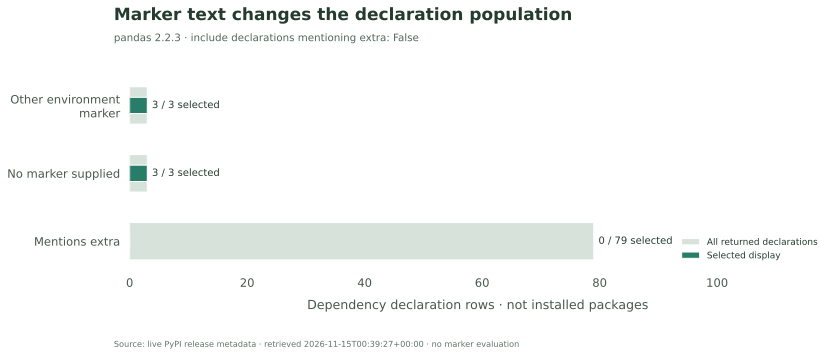

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.2))
y = np.arange(len(summary))
ax.barh(y, summary.declarations, color="#D6E2DA", height=0.55, label="All returned declarations")
ax.barh(y, summary.selected_declarations, color="#287D68", height=0.24, label="Selected display")
for i, r in enumerate(summary.itertuples()):
    ax.text(
        r.declarations + 0.8,
        i,
        f"{r.selected_declarations} / {r.declarations} selected",
        va="center",
        fontsize=10,
    )
ax.set(
    yticks=y,
    yticklabels=[
        x.replace("Other environment marker", "Other environment\nmarker") for x in summary.marker_group
    ],
    xlabel="Dependency declaration rows · not installed packages",
    xlim=(0, max(summary.declarations) * 1.5),
)
ax.legend(loc="lower right", fontsize=9)
finish(
    fig,
    "Marker text changes the declaration population",
    f"pandas 2.2.3 · include declarations mentioning extra: {INCLUDE_EXTRAS}",
    f"Source: live PyPI release metadata · retrieved {STARTED_UTC} · no marker evaluation",
    name=f"dependency-markers-{INCLUDE_EXTRAS}",
)

### Check the inventory boundary, not a solver's conclusion

Verify source identities, exact release/version selection, NULL retention and the local
filter. The known absence of a PyPI search index is intentional, so no search is attempted
there. npm results may hit their requested limit; the notebook labels that fact rather
than treating eight returned names as the entire registry.

In [13]:
%%sql checks <<
SELECT 'two configured package sources' AS check_name,count(*)=2 AND count(DISTINCT source_id)=2 AS passed FROM sources
UNION ALL SELECT 'anonymous settings',bool_and(authentication='anonymous' AND NOT credential_configured) FROM sources
UNION ALL SELECT 'five capabilities each',count(*)=10 AND count(DISTINCT(source_id,operation))=10 FROM capabilities
UNION ALL SELECT 'native and indexed readiness differ',(SELECT ready FROM source_status WHERE source_id='npm_public') AND NOT (SELECT ready FROM source_status WHERE source_id='pypi_public')
UNION ALL SELECT 'bounded native search',count(*)>0 AND count(*)<=8 AND bool_and(source_id='npm_public' AND search_mode='native') FROM search_results
UNION ALL SELECT 'search identities unique',count(*)=count(DISTINCT(source_id,name)) FROM search_results
UNION ALL SELECT 'exact project identity',count(*)=1 AND bool_and(name='pandas' AND source_id='pypi_public') FROM project
UNION ALL SELECT 'bounded version inventory',count(*)>0 AND count(*)<1000 FROM versions
UNION ALL SELECT 'target version exists',count(*)=1 FROM versions WHERE version='2.2.3'
UNION ALL SELECT 'exact release declarations',count(*)>0 AND count(*)<1000 AND bool_and(name='pandas' AND version='2.2.3' AND source_id='pypi_public') FROM declarations
UNION ALL SELECT 'native requirement and context retained',count(*)=count(requirement) AND count(*)=count(declaration_context) FROM declarations
UNION ALL SELECT 'both marker populations exist',count(*) FILTER(WHERE mentions_extra)>0 AND count(*) FILTER(WHERE NOT mentions_extra)>0 FROM declaration_flags
UNION ALL SELECT 'local filter agrees',bool_and(selected=({{INCLUDE_EXTRAS}} OR NOT mentions_extra)) FROM declaration_flags;

In [14]:
assert len(checks) == 13 and checks.passed.all()
display(checks)
_ = Path("artifacts/dependency-audit.json").write_text(
    json.dumps(
        {
            "parameter": INCLUDE_EXTRAS,
            "contract": contract.to_dict("records"),
            "declarations": connection.execute(
                "SELECT * FROM declaration_flags ORDER BY dependency,requirement"
            )
            .df()
            .to_dict("records"),
            "summary": summary.to_dict("records"),
            "selected": selected.to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
        default=str,
    )
    + "\n"
)
prose(
    f"All **{len(checks)} SQL controls** pass. Discovery, native version inventory and declaration conditions remain separate; no private registry or saved credential was consulted."
)

,check_name,passed
0,two configured package sources,True
1,anonymous settings,True
2,five capabilities each,True
3,native and indexed readiness differ,True
4,bounded native search,True
5,search identities unique,True
6,exact project identity,True
7,bounded version inventory,True
8,target version exists,True
9,exact release declarations,True


All **13 SQL controls** pass. Discovery, native version inventory and declaration conditions remain separate; no private registry or saved credential was consulted.

### Experiment: retain declarations that mention extras

Change **INCLUDE_EXTRAS from False to True**. The selected declaration count grows,
while the returned requirements and native conditions should remain the same if PyPI
metadata is unchanged. Compare retrieval timestamps and full requirement text before
attributing differences to the local filter. The readiness figure's values stay fixed;
its live timestamp changes. No environment marker is evaluated and no package is installed.
Restore False afterward.

In [15]:
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
public.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-software-packages](https://github.com/Query-farm/vgi-software-packages)